# 15. Conjuntos de chaves, estratos e vetores de deslocamento

Este notebook descreve a sobreposição entre o CNEFE e o BHMap e o deslocamento dos pares formados pela chave de logradouro e número. Ele parte das bases processadas do [NB01](01_ingestao.ipynb) e do pareamento do [NB02](02_matching.ipynb) e responde a quatro perguntas.

1. Quantos registros e quantas chaves cada base tem, e quantas chaves elas compartilham sob três regras de normalização?
2. Como a parcela de registros com par e o deslocamento variam entre apartamentos, estabelecimentos e vilas e favelas?
3. As chaves com mais de uma coordenada candidata no BHMap se comportam de modo diferente das que têm uma só?
4. Como se distribui o deslocamento dos pares e como ele se vê no mapa?

As tabelas saem em `outputs/tables` e as figuras em `outputs/figures`, com o prefixo `nb15_`. O [NB16](16_adjudicacao_cadastral.ipynb) examina, a seguir, a evidência cadastral dos pares distantes e dos registros sem par.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/config.py').exists())
sys.path.insert(0, str(ROOT))
from src import config
from src.metrics import chave_identidade, separar_logradouro_numero, conciliar_logradouros
P = config.PROCESSED_DIR
T = config.TAB_DIR
F = config.FIG_DIR
for d in [T,F]:d.mkdir(parents=True,exist_ok=True)
cnefe = gpd.read_parquet(P/'cnefe_bh.parquet')
bh_total = gpd.read_parquet(P/'bhmap_bh.parquet')
bh = bh_total.copy()
ident = pd.read_parquet(P/'cnefe_identidade.parquet')
assert cnefe.index.is_unique
assert ident.index.equals(cnefe.index)
assert np.array_equal(cnefe.COD_UNICO_ENDERECO.to_numpy(), ident.COD_UNICO_ENDERECO.to_numpy())
print('Bases:', len(cnefe), len(bh_total), len(bh))

Bases: 1180102 757113 757113


As bases de entrada têm 1.180.102 registros do CNEFE, 757.113 pontos do BHMap, todos usados como referência de comparação, dos quais 515.953 têm placa de número.

## 1. Registros, atributos e chaves de endereço

Um registro é uma linha da base, e uma chave é um par distinto de logradouro canônico e número. A chave principal reduz o número à primeira sequência de dígitos e concilia a grafia dos logradouros do CNEFE com o vocabulário do BHMap. Duas regras alternativas mostram a sensibilidade dessa escolha. A exata não concilia grafias, e a terceira preserva o sufixo alfabético do número (10 e 10A deixam de coincidir). A tabela de etapas segue cada base da entrada até a chave, e o inventário de atributos registra tipos, ausências e cardinalidades.

In [2]:
log_c_bruto,num_c_bruto=separar_logradouro_numero(cnefe.LOGRAD_NUM)
log_c,num_c=chave_identidade(log_c_bruto,num_c_bruto)
log_b,num_b=chave_identidade(bh.SIGLA_TIPO.fillna('')+' '+bh.NOME_LOGRA.fillna(''),bh.NUMERO_IMO)
log_b.index=bh.index
num_b.index=bh.index
mapa=conciliar_logradouros(log_c.unique(),log_b.unique(),limiar=90,margem=2)
log_conciliado=log_c.map(lambda v:mapa.get(v,v))
def chave(log,num):
    valida=log.notna() & log.ne('') & num.notna()
    return (log.astype('string')+'|'+num.astype('string')).where(valida)
def numero_com_sufixo(serie):
    texto=serie.astype('string').str.upper().str.strip().str.replace(r'^(\d+)\.0$',r'\1',regex=True)
    partes=texto.str.extract(r'^0*(\d+)\s*([A-Z]?)$')
    numero=partes[0].str.lstrip('0').replace('',pd.NA)
    return numero+partes[1].fillna('')
C=pd.DataFrame(index=cnefe.index)
C['exata']=chave(log_c,num_c)
C['conciliada']=chave(log_conciliado,num_c)
C['sufixo']=chave(log_conciliado,numero_com_sufixo(num_c_bruto))
B=pd.DataFrame(index=bh.index)
B['historica']=chave(log_b,num_b)
num_b_sufixo=numero_com_sufixo(bh.NUMERO_IMO)
B['sufixo']=chave(log_b,num_b_sufixo)
contagens=pd.DataFrame([
 {'base':'CNEFE','etapa':'registros ingeridos de BH','n':len(cnefe)},
 {'base':'CNEFE','etapa':'identificadores COD_UNICO_ENDERECO distintos','n':cnefe.COD_UNICO_ENDERECO.nunique()},
 {'base':'CNEFE','etapa':'repeticoes de COD_UNICO_ENDERECO','n':int(cnefe.COD_UNICO_ENDERECO.duplicated().sum())},
 {'base':'CNEFE','etapa':'registros com chave historica valida','n':int(C.exata.notna().sum())},
 {'base':'CNEFE','etapa':'registros com complemento informado','n':int(cnefe.COMPLEMENTO.fillna('').str.strip().ne('').sum())},
 {'base':'BHMap','etapa':'pontos de endereco (referencia completa)','n':len(bh_total)},
 {'base':'BHMap','etapa':'pontos com placa (EXISTENCIA = Sim), atributo','n':int(bh_total.EXISTENCIA.eq('Sim').sum())},
 {'base':'BHMap','etapa':'pontos com chave valida','n':int(B.historica.notna().sum())}])
contagens.to_csv(T/'nb15_contagens_etapas.csv',index=False)
atributos=[]
for nome,df in [('CNEFE',cnefe),('BHMap_total',bh_total),('BHMap_referencia',bh)]:
 for col in df.columns:
  if col=='geometry':continue
  atributos.append({'base':nome,'atributo':col,'tipo':str(df[col].dtype),'n':len(df),'ausentes':int(df[col].isna().sum()),'distintos':int(df[col].nunique())})
pd.DataFrame(atributos).to_csv(T/'nb15_inventario_atributos.csv',index=False)
conjuntos=[]
for nome,ck,bk in [('exata',C.exata,B.historica),('conciliada',C.conciliada,B.historica),('sufixo_preservado',C.sufixo,B.sufixo)]:
 A=set(ck.dropna());D=set(bk.dropna());I=A&D
 conjuntos.append({'regra':nome,'chaves_cnefe':len(A),'chaves_bhmap':len(D),'intersecao':len(I),'somente_cnefe':len(A-D),'somente_bhmap':len(D-A),'registros_cnefe_com_chave_comum':int(ck.isin(I).sum()),'registros_bhmap_com_chave_comum':int(bk.isin(I).sum())})
 assert len(A)==len(I)+len(A-D) and len(D)==len(I)+len(D-A)
conjuntos=pd.DataFrame(conjuntos)
conjuntos.to_csv(T/'nb15_conjuntos_enderecos.csv',index=False)
print(contagens.to_string(index=False));print(conjuntos.to_string(index=False))

 base                                         etapa       n
CNEFE                     registros ingeridos de BH 1180102
CNEFE  identificadores COD_UNICO_ENDERECO distintos 1173641
CNEFE              repeticoes de COD_UNICO_ENDERECO    6461
CNEFE          registros com chave historica valida 1157750
CNEFE           registros com complemento informado  690016
BHMap      pontos de endereco (referencia completa)  757113
BHMap pontos com placa (EXISTENCIA = Sim), atributo  515953
BHMap                       pontos com chave valida  757113
            regra  chaves_cnefe  chaves_bhmap  intersecao  somente_cnefe  somente_bhmap  registros_cnefe_com_chave_comum  registros_bhmap_com_chave_comum
            exata        456167        613763      386545          69622         227218                          1025630                           505822
       conciliada        456022        613763      404796          51226         208967                          1062044                           53068

O CNEFE tem 1.180.102 registros, mas só 1.173.641 identificadores distintos, porque 6.461 códigos se repetem. O identificador do IBGE não serve, sozinho, como chave única. Todos os 757.113 pontos do BHMap formam chave válida.

Pela regra conciliada, as duas bases compartilham 404.796 chaves, e 1.062.044 registros do CNEFE têm chave presente no BHMap. São registros, não endereços distintos, porque os apartamentos de um mesmo edifício repetem a chave da porta. A regra exata compartilha 386.545 chaves e pareia 1.025.630 registros, de modo que a conciliação recupera cerca de 36 mil registros. Preservar o sufixo do número faz o CNEFE saltar de 456.022 para 552.122 chaves e reduz as comuns a 390.359, porque separa chaves que a regra principal junta. O [NB22](22_conjuntos_exclusivos.ipynb) decompõe as chaves exclusivas de cada base.

## 2. Verticalização, vilas e estabelecimentos

Os estratos são descritos sobre o CNEFE inteiro, sem excluir os registros sem par. A parcela de registros com chave comum ao BHMap mede quantos endereços do Censo podem ser comparados, e não a completude do território. As vilas e favelas vêm da camada municipal, por inclusão geométrica. O uso separa domicílios, estabelecimentos e edificações em construção pela espécie do endereço.

In [3]:
vf=gpd.read_parquet(P/'vila_favela.parquet').to_crs(cnefe.crs).dissolve()
C['em_favela']=gpd.sjoin(cnefe[['geometry']],vf[['geometry']],how='left',predicate='within')['index_right'].notna().reindex(cnefe.index)
B['em_favela']=gpd.sjoin(bh[['geometry']],vf[['geometry']],how='left',predicate='within')['index_right'].notna().reindex(bh.index)
C['tipo']=np.where(cnefe.COD_TIPO_ESPECI.eq(103).fillna(False).to_numpy(dtype=bool),'apartamento','outras_tipologias')
C['uso']=np.select([cnefe.COD_ESPECIE.isin([3,4,5,6,8]),cnefe.COD_ESPECIE.isin([1,2])],['estabelecimento','domicilio'],default='construcao_ou_outro')
I=set(C.conciliada.dropna())&set(B.historica.dropna())
linhas=[]
for campo in ['em_favela','tipo','uso']:
 for valor,g in C.groupby(campo):
  d=ident.loc[g.index]
  des=d.loc[d.pareado_identidade,'dist_identidade']
  linhas.append({'base':'CNEFE','estrato':campo,'valor':str(valor),'registros':len(g),'chaves_validas':g.conciliada.nunique(),'chaves_comuns':g.loc[g.conciliada.isin(I),'conciliada'].nunique(),'registros_com_chave_comum':int(g.conciliada.isin(I).sum()),'verificabilidade_pct':100*g.conciliada.isin(I).mean(),'mediana_deslocamento_m':des.median(),'p90_m':des.quantile(.9),'acima100_pct':100*des.gt(100).mean()})
estratos=pd.DataFrame(linhas)
estratos.to_csv(T/'nb15_estratos_registros.csv',index=False)
print(estratos.to_string(index=False))
por_especie=cnefe.groupby('COD_ESPECIE').size().rename('registros').to_frame()
por_especie['descricao']=por_especie.index.map(config.ESPECIE_MAP)
por_especie.to_csv(T/'nb15_especies_cnefe.csv')
territorio=[]
for nome,df,k in [('CNEFE',C,'conciliada'),('BHMap',B,'historica')]:
 for valor,g in df.groupby('em_favela'):
  keys=set(g[k].dropna())
  territorio.append({'base':nome,'em_favela':bool(valor),'registros':len(g),'chaves':len(keys),'chaves_comuns_global':len(keys&I),'chaves_exclusivas_global':len(keys-I)})
pd.DataFrame(territorio).to_csv(T/'nb15_conjuntos_territorio.csv',index=False)

 base   estrato               valor  registros  chaves_validas  chaves_comuns  registros_com_chave_comum  verificabilidade_pct  mediana_deslocamento_m     p90_m  acima100_pct
CNEFE em_favela               False    1051953          392257         359527                     969350             92.147653                9.783445 35.043418      2.455047
CNEFE em_favela                True     128149           69999          50590                      92694             72.332987               10.394014 43.205425      6.448098
CNEFE      tipo         apartamento     403623           37073          35104                     385346             95.471764               13.942887 56.030179      3.768821
CNEFE      tipo   outras_tipologias     776479          431747         381826                     676698             87.149556                8.348192 23.276402      2.253886
CNEFE       uso construcao_ou_outro      19297           13184          11047                      13557             70.25444

A parcela comparável cai de 92,1% fora das vilas e favelas para 72,3% dentro delas, onde a cauda acima de 100 m chega a 6,4% dos pares, contra 2,5% no restante da cidade. Os apartamentos são os mais comparáveis (95,5%), mas têm a maior mediana de deslocamento (13,9 m) e o maior P90 (56,0 m), porque o ponto do BHMap fica dentro do lote e o do Censo representa a unidade padronizada pelo IBGE. Os estabelecimentos ficam em 86,4% e as edificações em construção em 70,3%. As chaves podem aparecer em mais de um estrato, e por isso as contagens distintas não devem ser somadas entre estratos.

## 3. Chaves com mais de uma coordenada candidata

Quando uma chave tem mais de uma coordenada no BHMap, o pareamento escolhe a mais próxima. Isso minimiza a distância e pode tornar a medida otimista. Contamos quantos registros pareados estão nessa situação e comparamos a distribuição do deslocamento entre chaves com uma e com várias coordenadas.

In [4]:
ref=pd.DataFrame({'chave':B.historica,'x':bh.geometry.x,'y':bh.geometry.y}).dropna()
n_candidatos=ref.drop_duplicates(['chave','x','y']).groupby('chave').size()
C['n_coordenadas_referencia']=C.conciliada.map(n_candidatos).fillna(0).astype(int)
C['grafia_conciliada']=log_c.ne(log_conciliado)
C['pareado']=ident.pareado_identidade
C['cauda100']=ident.dist_identidade.gt(100)
C['ambiguo_qualquer']=C.n_coordenadas_referencia.gt(1)
amb=C.groupby(['n_coordenadas_referencia','cauda100']).size().rename('n').reset_index()
amb.to_csv(T/'nb15_ambiguidades_referencia.csv',index=False)
resumo_amb=[]
for nome,mask in [('todos_pareados',C.pareado),('referencia_uma_coordenada',C.pareado & C.n_coordenadas_referencia.eq(1)),('referencia_multiplas_coordenadas',C.pareado & C.ambiguo_qualquer)]:
 d=ident.loc[mask,'dist_identidade']
 resumo_amb.append({'grupo':nome,'n':len(d),'mediana_m':d.median(),'p90_m':d.quantile(.9),'acima100_pct':100*d.gt(100).mean()})
pd.DataFrame(resumo_amb).to_csv(T/'nb15_sensibilidade_ambiguidades.csv',index=False)
print(pd.DataFrame(resumo_amb).to_string(index=False))
print(amb.assign(cauda100=amb.cauda100.map({True:'acima de 100 m',False:'até 100 m'})).pivot(index='n_coordenadas_referencia',columns='cauda100',values='n').fillna(0).astype(int).head(8).to_string())

                           grupo       n  mediana_m     p90_m  acima100_pct
                  todos_pareados 1062044   9.837064 35.589708      2.803556
       referencia_uma_coordenada  818588  10.541798 38.397192      2.800065
referencia_multiplas_coordenadas  243456   7.729157 24.236475      2.815293
cauda100                  acima de 100 m  até 100 m
n_coordenadas_referencia                           
0                                      0     118058
1                                  22921     795667
2                                   3842     137842
3                                   1431      57606
4                                    747      23868
5                                    410       9543
6                                    196       4059
7                                    111       1897


Dos 1.062.044 registros pareados, 818.588 têm uma única coordenada candidata e 243.456 têm várias. Nas chaves com várias coordenadas, a mediana cai para 7,7 m e o P90 para 24,2 m, contra 10,5 m e 38,4 m nas chaves com uma só, efeito esperado de escolher o candidato mais próximo. A cauda acima de 100 m, porém, é praticamente igual nos dois grupos (2,8%), e escolher o candidato mais próximo não a reduz. Os homônimos que ela reúne são examinados no NB16.

## 4. Distribuição e vetores do deslocamento pela chave

O histograma, em escala logarítmica, mostra a distância de cada registro pareado ao ponto do BHMap com a mesma chave, sem truncamento, e a curva acumulada ao lado mostra a mesma distribuição. O mapa liga a coordenada do CNEFE ao ponto do BHMap numa amostra de 500 pares com uma única coordenada candidata, sorteada com semente fixa numa faixa de 5 km no sentido norte-sul que atravessa o centro da cidade.

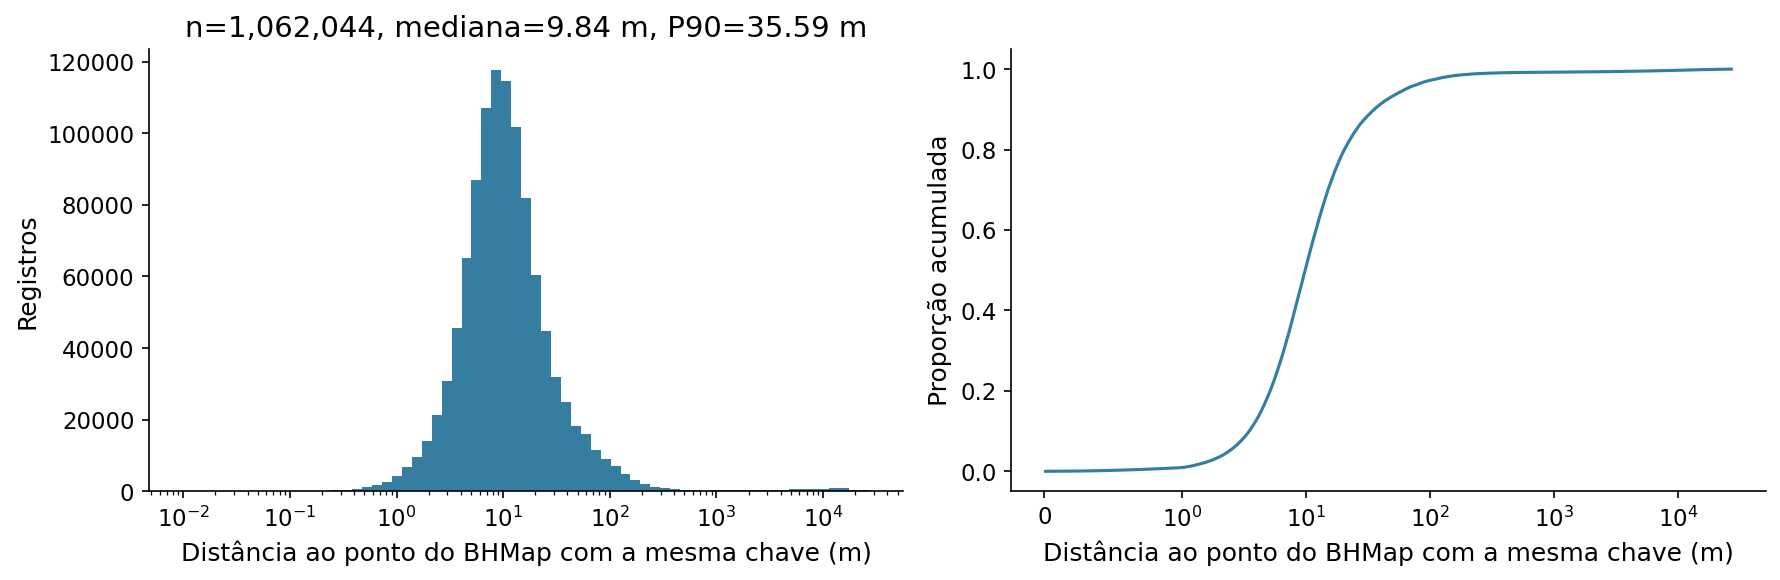

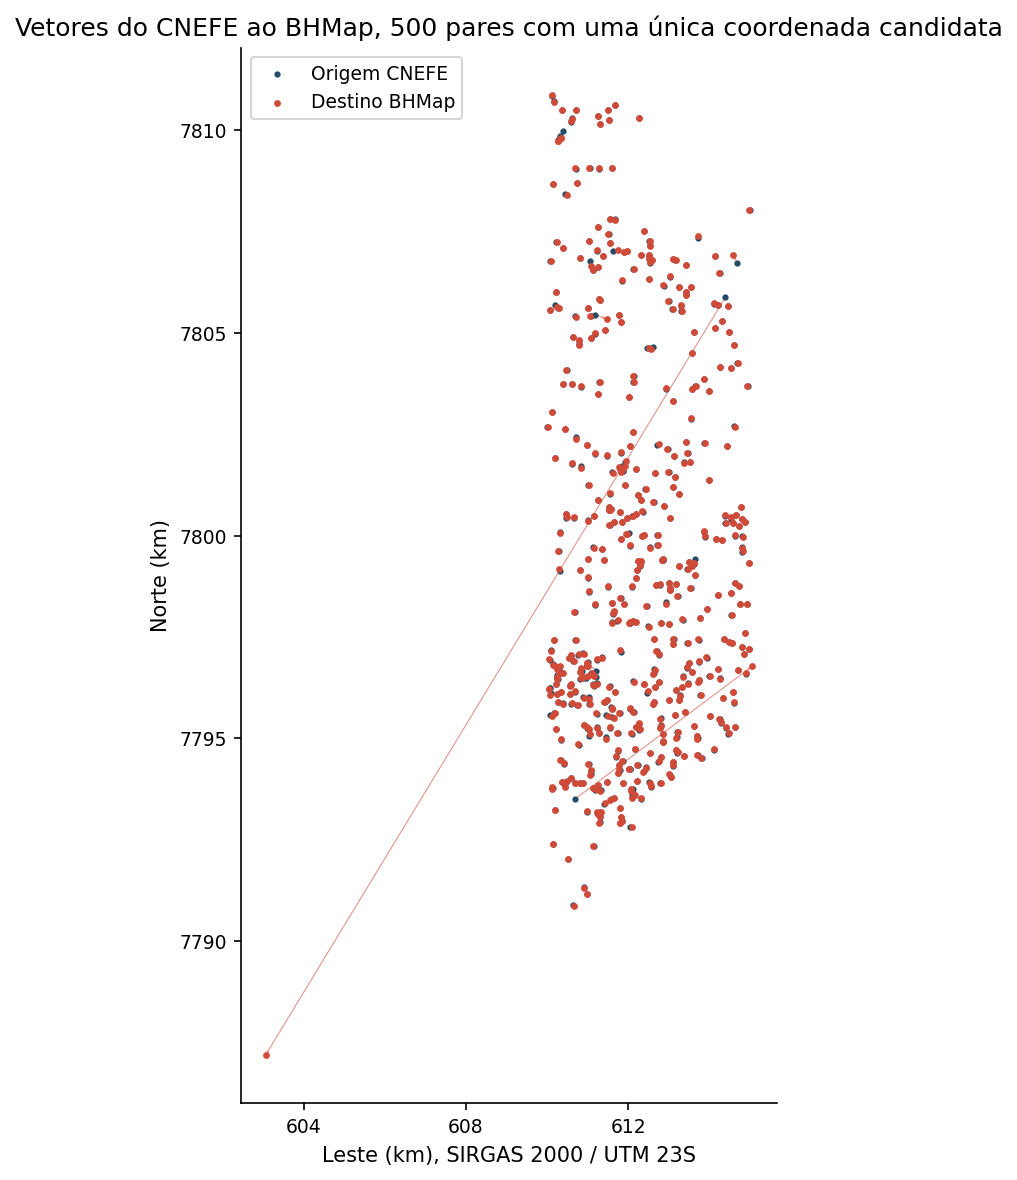

{
  "n_cnefe": 1180102,
  "n_bhmap_existente": 757113,
  "n_pareados_chave": 1062044,
  "mediana_m": 9.837064278417728,
  "p90_m": 35.58970751114782,
  "cauda100_pct": 2.8035561615149653,
  "conciliacoes_logradouro": 1335
}


In [5]:
d=ident.loc[ident.pareado_identidade,'dist_identidade']
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(d,bins=np.geomspace(max(.01,d[d>0].min()),d.max()+1,70),color='#367EA1')
axes[0].set_xscale('log');axes[0].set(xlabel='Distância ao ponto do BHMap com a mesma chave (m)',ylabel='Registros',title=f'n={len(d):,}, mediana={d.median():.2f} m, P90={d.quantile(.9):.2f} m')
v=np.sort(d.to_numpy());axes[1].plot(v,np.arange(1,len(v)+1)/len(v),color='#367EA1')
axes[1].set_xscale('symlog',linthresh=1);axes[1].set(xlabel='Distância ao ponto do BHMap com a mesma chave (m)',ylabel='Proporção acumulada')
fig.tight_layout();fig.savefig(F/'nb15_histograma_identidade.png',dpi=200);plt.show()
mask=C.pareado & C.n_coordenadas_referencia.eq(1)
centro=cnefe[mask & cnefe.geometry.x.between(610000,615000)]
if len(centro)<100:centro=cnefe[mask]
sel=centro.sample(min(500,len(centro)),random_state=42)
r=ident.loc[sel.index]
from matplotlib.ticker import MaxNLocator, FuncFormatter
fig,ax=plt.subplots(figsize=(8,8))
ax.quiver(sel.geometry.x,sel.geometry.y,r.ref_x.to_numpy()-sel.geometry.x.to_numpy(),r.ref_y.to_numpy()-sel.geometry.y.to_numpy(),angles='xy',scale_units='xy',scale=1,width=.002,alpha=.6,color='#D04A38')
ax.scatter(sel.geometry.x,sel.geometry.y,s=4,label='Origem CNEFE',color='#264B67')
ax.scatter(r.ref_x,r.ref_y,s=5,label='Destino BHMap',color='#D04A38')
ax.set(xlabel='Leste (km), SIRGAS 2000 / UTM 23S',ylabel='Norte (km)',title=f'Vetores do CNEFE ao BHMap, {len(sel)} pares com uma única coordenada candidata')
ax.xaxis.set_major_locator(MaxNLocator(4))
ax.yaxis.set_major_locator(MaxNLocator(6))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos: f'{x/1000:.0f}'))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y,pos: f'{y/1000:.0f}'))
ax.tick_params(labelsize=9)
ax.title.set_fontsize(12)
ax.xaxis.label.set_fontsize(10)
ax.yaxis.label.set_fontsize(10)
ax.set_aspect('equal');ax.legend(fontsize=9);fig.tight_layout();fig.savefig(F/'nb15_vetores_identidade.png',dpi=200);plt.show()
resultado={'n_cnefe':len(cnefe),'n_bhmap_existente':len(bh),'n_pareados_chave':len(d),'mediana_m':float(d.median()),'p90_m':float(d.quantile(.9)),'cauda100_pct':float(100*d.gt(100).mean()),'conciliacoes_logradouro':len(mapa)}
(T/'nb15_resumo.json').write_text(json.dumps(resultado,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps(resultado,ensure_ascii=False,indent=2))

A distribuição é concentrada e assimétrica. A mediana é de 9,84 m e o P90 de 35,59 m, mas a cauda se estende por quilômetros, e 2,8% dos pares ficam a mais de 100 m. No mapa, a escala da faixa esconde os vetores de dezenas de metros, que ficam sob os próprios pontos. Só aparecem como linhas os poucos pares a quilômetros de distância, que ligam endereços em partes diferentes da cidade. Esses vetores longos são o objeto do NB16.

## Conclusão

As duas bases compartilham 404.796 chaves pela regra conciliada, e 90,0% dos registros do CNEFE encontram par. A conciliação de grafia recupera cerca de 36 mil registros, e preservar o sufixo do número separa chaves em vez de juntá-las. A parcela comparável é menor nas vilas e favelas e entre os estabelecimentos. Os apartamentos são os mais comparáveis, mas os mais distantes do ponto municipal. Escolher o candidato mais próximo afeta 243.456 registros e reduz a distância nesse grupo, sem reduzir a cauda. O deslocamento tem mediana de 9,84 m, P90 de 35,59 m e uma cauda longa de 2,8% acima de 100 m.

O [NB16](16_adjudicacao_cadastral.ipynb) usa o cadastro fiscal para separar, na cauda e entre os registros sem par, os padrões de representação, de correspondência e de coordenada.